In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
#import regressors
#from regressors import stats
import statsmodels.api as sm


sns.set(style= "whitegrid", context= "notebook") #Establecer estilo de las graficas

df= pd.read_csv("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Regresion_lineal_con_sklearn/insurance.csv", sep= ",")
#df= pd.read_csv("C:/Users/Sebastian Zapata/Documents/Sebastian - FUNDAEC/ciencia_de_datos/insurance.csv", sep= ",")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
%run "C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Regresion_lineal_con_sklearn/detect_outliers.ipynb"

(1338, 7)


<Axes: >

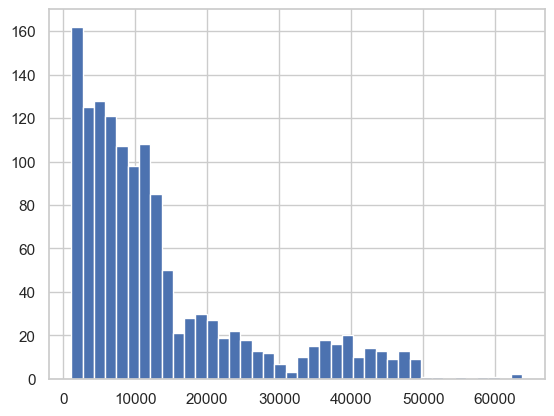

In [2]:
print(df.shape)

df.charges.hist(bins= 40)

In [3]:
df[df.charges> 50000] #Observar los datos de la columna "charges" mayores a 50000
df= df[df.charges < 50000] #Crear un dataset con los datos de la columna "charges" menores a 50000

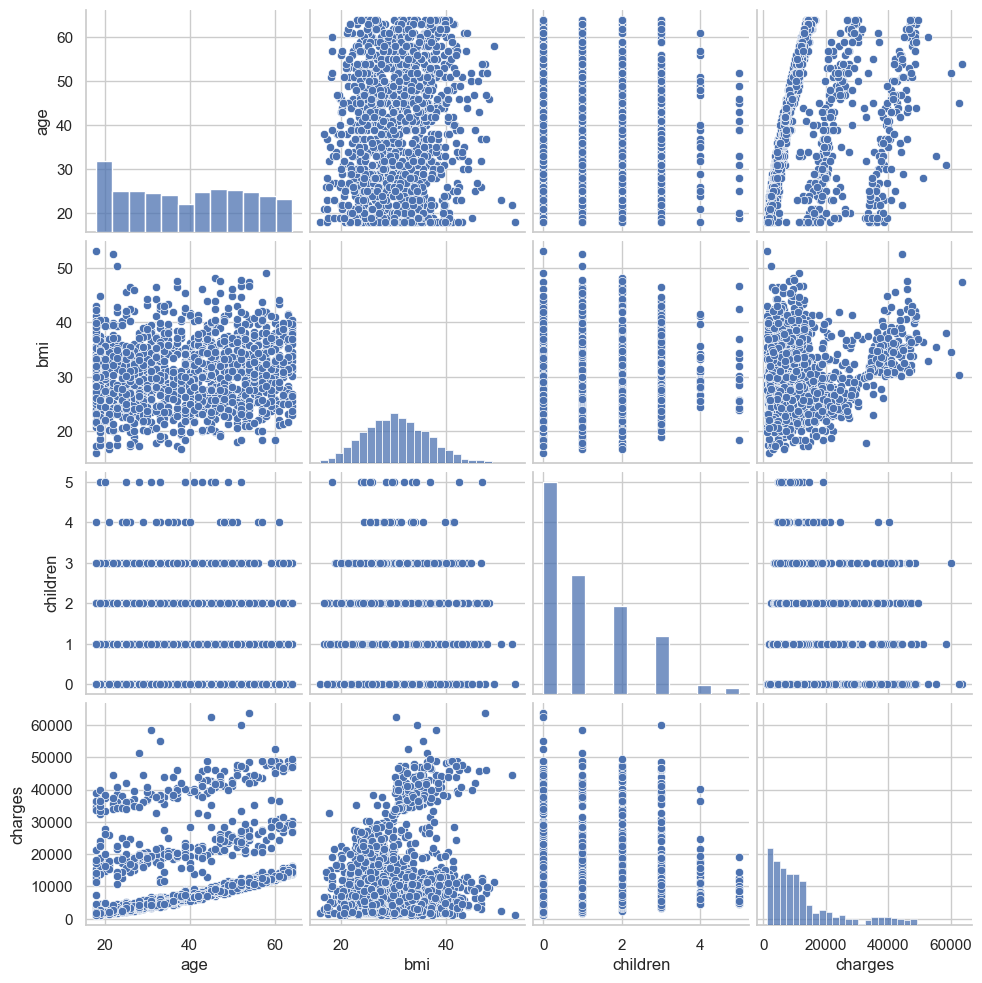

In [4]:
#ENCONTRAR CORRELACIONES

sns.pairplot(df, height= 2.5)

<Axes: >

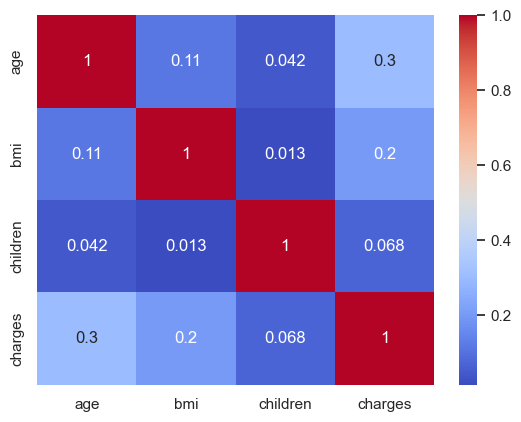

In [2]:
num_cols= df.select_dtypes(include=["int64", "float64"]).columns
df_numeric= df[num_cols]

sns.heatmap(df_numeric.corr(), annot= True, cmap= "coolwarm")

In [3]:
df= pd.get_dummies(df, columns= ["sex", "smoker", "region"], drop_first= True) #One hot encoding
df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [4]:
#CREAR EL MODELO DE REGRESION LINEAL

X = df.drop(columns=["charges"])
y = df["charges"]

#Seleccionar los valores 
X = X.values
y = y.values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25) #Dividir los datos de entrenamiento y prueba

# Estandarizar y normalizar los datos
sc_x = StandardScaler()
X_train = sc_x.fit_transform(X_train)
X_test = sc_x.transform(X_test)

# Convertir a DataFrame para mantener los nombres de las columnas
X_train_df = pd.DataFrame(X_train, columns=df.drop(columns=["charges"]).columns)
X_test_df = pd.DataFrame(X_test, columns=df.drop(columns=["charges"]).columns)

# Estandarizar la variable objetivo
sc_y = StandardScaler()
y_train = sc_y.fit_transform(y_train)
y_test = sc_y.transform(y_test)

#Crear el modelo
model = LinearRegression()
model.fit(X_train, y_train)

#Predecir
y_pred = model.predict(X_test)

In [5]:
#EVALUANDO EL MODELO

mse= metrics.mean_squared_error(y_test, y_pred)
r2= metrics.r2_score(y_test, y_pred)

print(f"R2: {r2.round(3)}")
print(f"MSE: {mse.round(3)}")

R2: 0.77
MSE: 0.25


In [6]:
# Para statsmodels, añadir una constante
X_train_sm = sm.add_constant(X_train_df)
X_test_sm = sm.add_constant(X_test_df)

# Crear el modelo OLS y ajustar
model_sm = sm.OLS(y_train, X_train_sm)
results = model_sm.fit()

# Mostrar el resumen del modelo statsmodels
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.741
Method:                 Least Squares   F-statistic:                     360.2
Date:                Fri, 17 May 2024   Prob (F-statistic):          1.71e-287
Time:                        22:23:03   Log-Likelihood:                -740.81
No. Observations:                1003   AIC:                             1500.
Df Residuals:                     994   BIC:                             1544.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.821e-17      0.016  

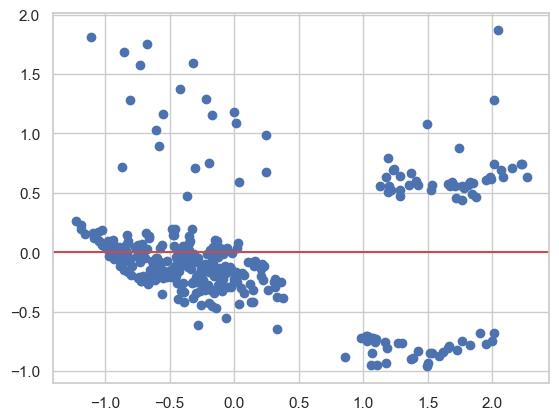

In [8]:
#GRAFICAR LOS RESIDUALES
residuals= np.subtract(y_test, y_pred) #La idea es que los valores se situen sobre el 0
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='r', linestyle='-')

In [9]:
#MEJORAR EL MODELO

#Crear nuevas variables
df_second= df.copy() # Crear una copia del df

df_second["age2"] = df_second.age **2
df_second["sobrepeso"] = (df_second.bmi >=30).astype(int) #Convertir a entero
df_second["sobrepeso*fumador"] = df_second.sobrepeso * df_second.smoker_yes

In [10]:
#CREAR EL MODELO MEJORADO

# Asume que df_second ya está definido y contiene los datos
X = df_second.drop(columns=["charges"])
y = df_second["charges"]

# Seleccionar los valores 
X = X.values
y = y.values.reshape(-1, 1)

# Dividir los datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Estandarizar los datos
sc_x = StandardScaler()
X_train = sc_x.fit_transform(X_train)
X_test = sc_x.transform(X_test)

# Convertir a DataFrame para mantener los nombres de las columnas
X_train_df = pd.DataFrame(X_train, columns=df_second.drop(columns=["charges"]).columns)
X_test_df = pd.DataFrame(X_test, columns=df_second.drop(columns=["charges"]).columns)

# Estandarizar la variable objetivo
sc_y = StandardScaler()
y_train = sc_y.fit_transform(y_train)
y_test = sc_y.transform(y_test)

# Crear el modelo de regresión lineal
model = LinearRegression()
model.fit(X_train_df, y_train)

# Predecir
y_pred = model.predict(X_test_df)

In [11]:
mse= metrics.mean_squared_error(y_test, y_pred)
r2= metrics.r2_score(y_test, y_pred)

print(f"R2: {r2.round(3)}")
print(f"MSE: {mse.round(3)}")

R2: 0.867
MSE: 0.139


In [12]:
# Para statsmodels, añadir una constante
X_train_sm = sm.add_constant(X_train_df)
X_test_sm = sm.add_constant(X_test_df)

# Crear el modelo OLS y ajustar
model_sm = sm.OLS(y_train, X_train_sm)
results = model_sm.fit()

# Mostrar el resumen del modelo statsmodels
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.866
Model:                            OLS   Adj. R-squared:                  0.865
Method:                 Least Squares   F-statistic:                     582.8
Date:                Fri, 17 May 2024   Prob (F-statistic):               0.00
Time:                        22:26:25   Log-Likelihood:                -414.79
No. Observations:                1003   AIC:                             853.6
Df Residuals:                     991   BIC:                             912.5
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const             -1.587e-16      0.01

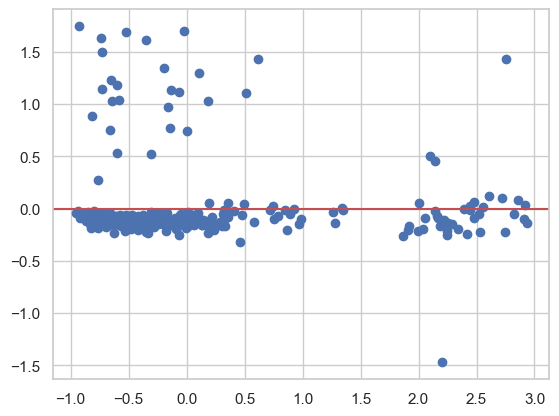

In [13]:
residuals= np.subtract(y_test, y_pred) #Graficar los residuales. La idea es que los valores se situen sobre el 0
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='r', linestyle='-')

In [14]:
#SEGUNDA MEJORA

# Asume que df_second ya está definido y contiene los datos
X = df_second[["bmi", "children", "smoker_yes", "region_southwest", "age2"]]
y = df_second["charges"]

# Seleccionar los valores 
X = X.values
y = y.values.reshape(-1, 1)

# Dividir los datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Estandarizar los datos
sc_x = StandardScaler()
X_train = sc_x.fit_transform(X_train)
X_test = sc_x.transform(X_test)

# Convertir a DataFrame para mantener los nombres de las columnas
selected_columns = ["bmi", "children", "smoker_yes", "region_southwest", "age2"]
X_train_df = pd.DataFrame(X_train, columns=selected_columns)
X_test_df = pd.DataFrame(X_test, columns=selected_columns)

# Estandarizar la variable objetivo
sc_y = StandardScaler()
y_train = sc_y.fit_transform(y_train)
y_test = sc_y.transform(y_test)

# Crear el modelo de regresión lineal
model = LinearRegression()
#model = LinearRegression(fit_intercept= False) #Si quiero eliminar el intercepto
model.fit(X_train_df, y_train)

# Predecir
y_pred = model.predict(X_test_df)

In [15]:
mse= metrics.mean_squared_error(y_test, y_pred)
r2= metrics.r2_score(y_test, y_pred)

print(f"R2: {r2.round(3)}")
print(f"MSE: {mse.round(3)}")

R2: 0.767
MSE: 0.242


In [17]:
# Para statsmodels, añadir una constante
X_train_sm = sm.add_constant(X_train_df)
X_test_sm = sm.add_constant(X_test_df)

# Crear el modelo OLS y ajustar
model_sm = sm.OLS(y_train, X_train_sm)
results = model_sm.fit()

# Mostrar el resumen del modelo statsmodels
print(results.summary())


#ESTE "INTENTO" DE MEJORAR EL MODELO FUE ELIMINANDO LAS VARIABLES QUE TENIAN UN VALOR P < 0.05, sin embargo, el modelo disminuyo

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.748
Model:                            OLS   Adj. R-squared:                  0.746
Method:                 Least Squares   F-statistic:                     590.3
Date:                Fri, 17 May 2024   Prob (F-statistic):          5.76e-295
Time:                        22:27:35   Log-Likelihood:                -732.95
No. Observations:                1003   AIC:                             1478.
Df Residuals:                     997   BIC:                             1507.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.587e-16      0.016  

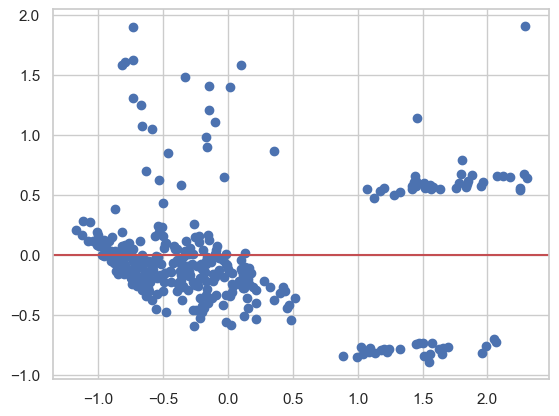

In [18]:
residuals= np.subtract(y_test, y_pred) #Graficar los residuales. La idea es que los valores se situen sobre el 0
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='r', linestyle='-')